# 01 · Exploratory data analysis (advanced)
**Rule:** this notebook only looks at **2017-2018** (train + validation). The 2019 test year is never opened here.
Every figure is saved to `results/figures/` for the report. Run the cells top to bottom (about 5-10 min in total).

In [17]:
import sys, os, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import holidays
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
from src import evaluate as ev, metrics as M

CCOL = {"C1_I580-E": "#0072B2", "C2_US101-N": "#E69F00", "C3_I880-S": "#009E73", "C4_SR24-W": "#D55E00"}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titleweight": "bold"})
facts = {}                                   # headline numbers, saved at the end for the report

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(ev.FIGS / f"{name}.png", dpi=150)
    plt.show()

## Load the data (2017-2018 only)

In [18]:
tab = ev.load_table(15)
eda = tab[tab["split"].isin(["train", "val"])].copy()          # 2019 rows are dropped here, on purpose
eda["tt_hour"] = eda["target_time"].dt.hour + eda["target_time"].dt.minute / 60
eda["offday"] = (eda["is_weekend"] > 0) | (eda["is_holiday"] > 0)
del tab

LAST = pd.Timestamp("2018-12-31 23:45")
F = pd.read_parquet(ev.DATA / "flow_15min_100.parquet").loc[:LAST]
sensors = pd.read_csv(ev.DATA / "sensors_100.csv")
sensors = sensors.set_index(sensors["ID2"].astype(str)).loc[F.columns]
cmap = sensors["corridor"]
W = pd.read_csv(ev.DATA / "weather_hourly.csv", parse_dates=["time"])
W = W[W["time"] <= LAST]
print("flow grid:", F.shape, F.index.min(), "->", F.index.max())
print("table rows used:", len(eda))

flow grid: (70080, 100) 2017-01-01 00:00:00 -> 2018-12-31 23:45:00
table rows used: 1343584


## 1. Data audit
What the cleaned 15-minute grid looks like, per corridor: how much is still missing after fault removal, how many
zeros, and how busy each corridor is.

In [19]:
aud = eda.groupby(["split", "corridor"]).agg(rows=("y", "size"), sensors=("ID2", "nunique"),
        mean_flow=("y_raw", "mean"), median_flow=("y_raw", "median"), p99_flow=("y_raw", lambda s: s.quantile(.99)),
        zero_share=("y_raw", lambda s: (s == 0).mean())).round(3)
display(aud)
miss = F.isna().T.groupby(cmap.to_numpy()).mean().T
miss_year = miss.groupby(miss.index.year).mean().round(4) * 100
print("\nMissing share of 15-minute bins after cleaning (%), by corridor and year:")
display(miss_year)
facts["missing_pct_2017_2018"] = float(F.isna().to_numpy().mean() * 100)

rows  sensors    mean_flow  median_flow  p99_flow  \
split corridor                                                          
train C1_I580-E   248412       20   843.520020        905.0    2147.0   
      C2_US101-N  248095       20  1092.675049       1210.0    2076.0   
      C3_I880-S   248175       20   881.700012        897.0    1849.0   
      C4_SR24-W   248315       20   785.117981        797.0    1893.0   
val   C1_I580-E    87917       20   844.794006        901.0    2155.0   
      C2_US101-N   87680       20  1087.495972       1195.0    2074.0   
      C3_I880-S    87482       20   852.836975        847.0    1751.0   
      C4_SR24-W    87508       20   772.250000        767.0    1867.0   

                  zero_share  
split corridor                
train C1_I580-E        0.006  
      C2_US101-N       0.001  
      C3_I880-S        0.000  
      C4_SR24-W        0.003  
val   C1_I580-E        0.007  
      C2_US101-N       0.002  
      C3_I880-S        0.002  
      C4_SR24-W        0.003


Missing share of 15-minute bins after cleaning (%), by corridor and year:


,C1_I580-E,C2_US101-N,C3_I880-S,C4_SR24-W
time,,,,
2017,0.05,0.14,0.12,0.13
2018,0.32,0.49,0.62,0.49


## 2. Figure 1 · Daily profile, weekday vs weekend/holiday
Weekdays show commute peaks; weekends one broad midday hump. Direction matters: SR-24 westbound peaks in the
morning, I-580 eastbound in the evening.

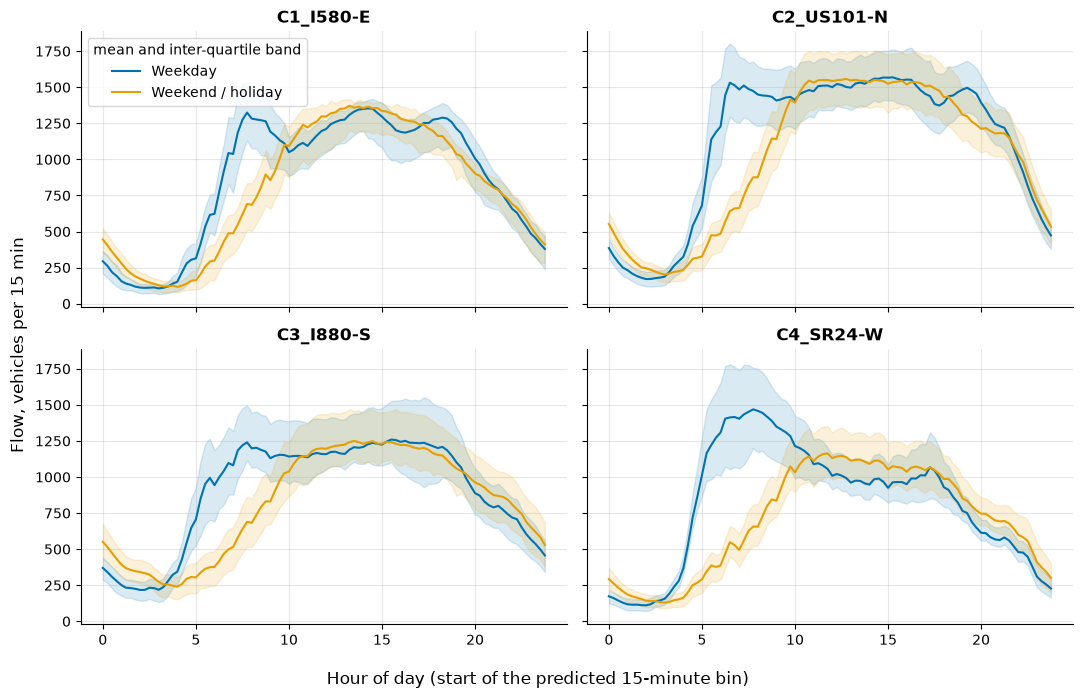

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (name, g) in zip(axes.ravel(), eda.groupby("corridor")):
    prof = g.groupby(["tt_hour", "offday"])["y_raw"].agg(["mean", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
    for flag, lab, col in ((False, "Weekday", "#0072B2"), (True, "Weekend / holiday", "#E69F00")):
        p = prof.xs(flag, level="offday")
        ax.plot(p.index, p["mean"], color=col, label=lab)
        ax.fill_between(p.index, p.iloc[:, 1], p.iloc[:, 2], color=col, alpha=0.15)
    ax.set_title(name)
axes[0, 0].legend(title="mean and inter-quartile band")
fig.supxlabel("Hour of day (start of the predicted 15-minute bin)"); fig.supylabel("Flow, vehicles per 15 min")
savefig(fig, "eda01_daily_profile")

## 3. Figure 2 · Weekly rhythm (relative load, day of week x time of day)
Each sensor is divided by its own mean first, so the colours show *relative* load (1.0 = that sensor's average).

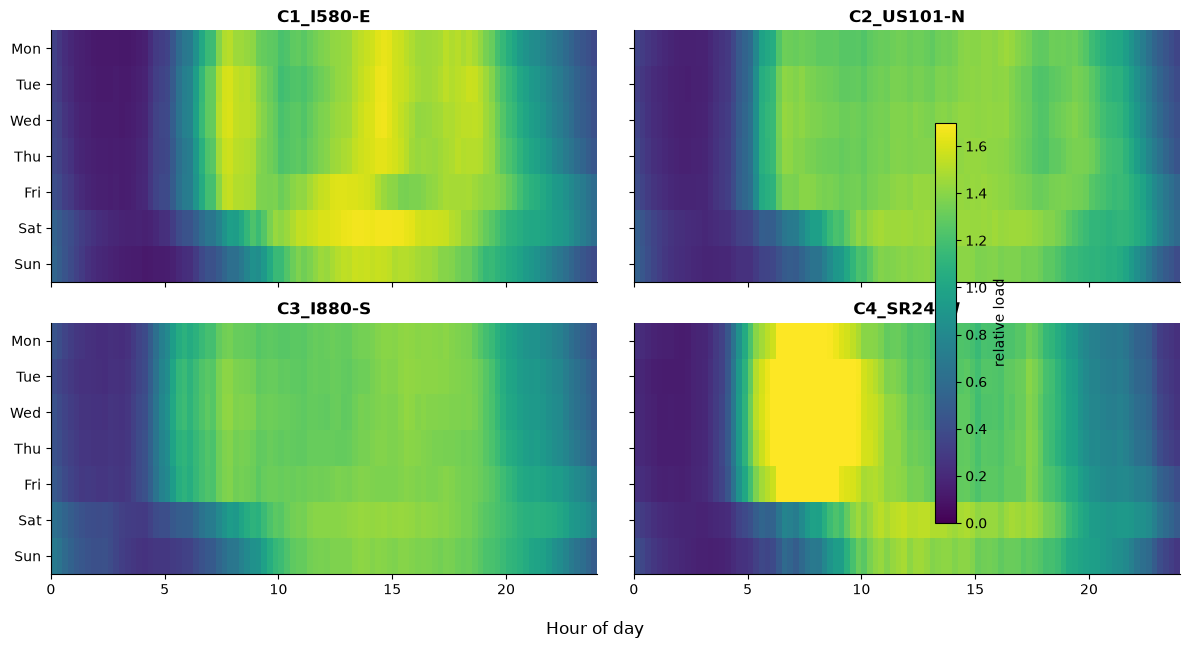

In [21]:
rel = F / F.mean()
rel_c = rel.T.groupby(cmap.to_numpy()).mean().T
slot = rel_c.index.hour * 4 + rel_c.index.minute // 15
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True, sharey=True)
for ax, c in zip(axes.ravel(), sorted(CCOL)):
    m = rel_c[c].groupby([rel_c.index.dayofweek, slot]).mean().unstack()
    im = ax.imshow(m.to_numpy(), aspect="auto", cmap="viridis", vmin=0, vmax=1.7,
                   extent=[0, 24, 6.5, -0.5])
    ax.set_title(c); ax.grid(False)
    ax.set_yticks(range(7)); ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
fig.supxlabel("Hour of day"); fig.colorbar(im, ax=axes, shrink=0.8, label="relative load")
savefig(fig, "eda02_weekly_heatmap")

## 4. Figure 3 · Day types and holidays
Total daily flow (sensors with at least 80 % valid bins that day), relative to each sensor's average, grouped into
weekday / Saturday / Sunday / public holiday. This quantifies what the `is_holiday` and `is_weekend` features carry.

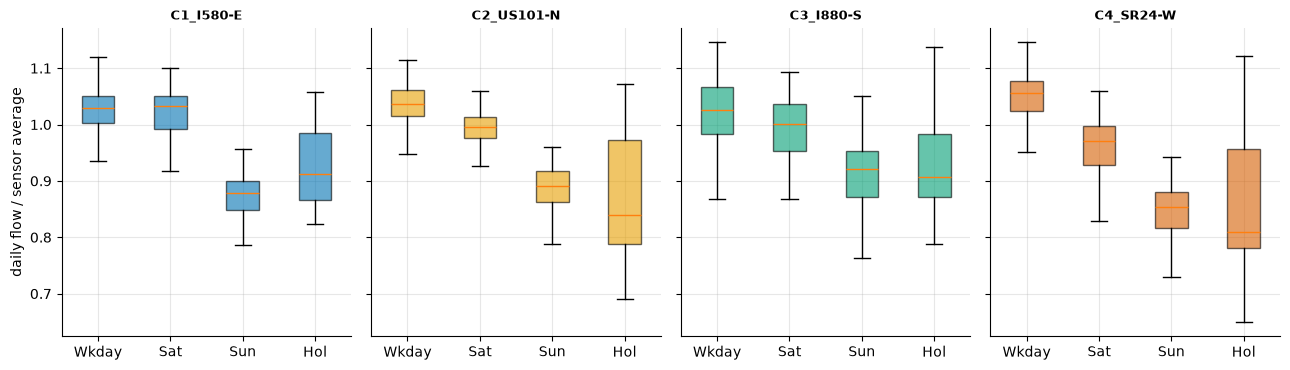

,C1_I580-E,C2_US101-N,C3_I880-S,C4_SR24-W
Weekday,1.029,1.037,1.025,1.056
Saturday,1.033,0.995,1.000,0.970
Sunday,0.879,0.891,0.921,0.854
Holiday (Mon-Fri),0.913,0.840,0.907,0.809



Lowest-traffic days:
  2017-01-08  0.69  Sunday
  2018-02-04  0.72  Sunday
  2017-02-26  0.75  Sunday
  2017-12-25  0.76  Christmas Day
  2017-12-31  0.76  Sunday
  2018-01-01  0.76  New Year's Day
  2017-01-22  0.77  Sunday
  2018-11-25  0.78  Sunday


In [22]:
cnt = F.notna().resample("D").sum()
daily = (F.resample("D").mean() * 96).where(cnt >= 77)
daily_rel = (daily / daily.mean()).T.groupby(cmap.to_numpy()).mean().T
ca = holidays.country_holidays("US", subdiv="CA", years=[2017, 2018])
dts = pd.Series(["Weekday"] * len(daily_rel), index=daily_rel.index)
dts[daily_rel.index.dayofweek == 5] = "Saturday"
dts[daily_rel.index.dayofweek == 6] = "Sunday"
is_hol = pd.Series(daily_rel.index.isin(pd.DatetimeIndex(sorted(ca.keys()))), index=daily_rel.index)
dts[is_hol & (daily_rel.index.dayofweek < 5)] = "Holiday (Mon-Fri)"
order = ["Weekday", "Saturday", "Sunday", "Holiday (Mon-Fri)"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=True)
tbl = {}
for ax, c in zip(axes, sorted(CCOL)):
    data = [daily_rel.loc[dts == k, c].dropna() for k in order]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False)
    ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels(["Wkday", "Sat", "Sun", "Hol"])
    for b in bp["boxes"]:
        b.set_facecolor(CCOL[c]); b.set_alpha(0.6)
    ax.set_title(c, fontsize=9)
    tbl[c] = [float(np.median(d)) for d in data]
axes[0].set_ylabel("daily flow / sensor average")
savefig(fig, "eda03_day_types")
tbl = pd.DataFrame(tbl, index=order).round(3)
display(tbl)
facts["weekend_vs_weekday_ratio"] = float((tbl.loc["Sunday"] / tbl.loc["Weekday"]).mean())
lowest = daily_rel.mean(axis=1).nsmallest(8)
print("\nLowest-traffic days:")
for d, v in lowest.items():
    print(f"  {d.date()}  {v:.2f}  {ca.get(d.date(), '') or d.day_name()}")

## 5. Figure 4 · Seasonality and year-on-year change
Weekly mean of weekday relative load per corridor. A slow trend or a level shift matters because the models see a
*trailing* scale: if the level moves, the scaling adapts, but the seasonal-last-week baseline lags behind.

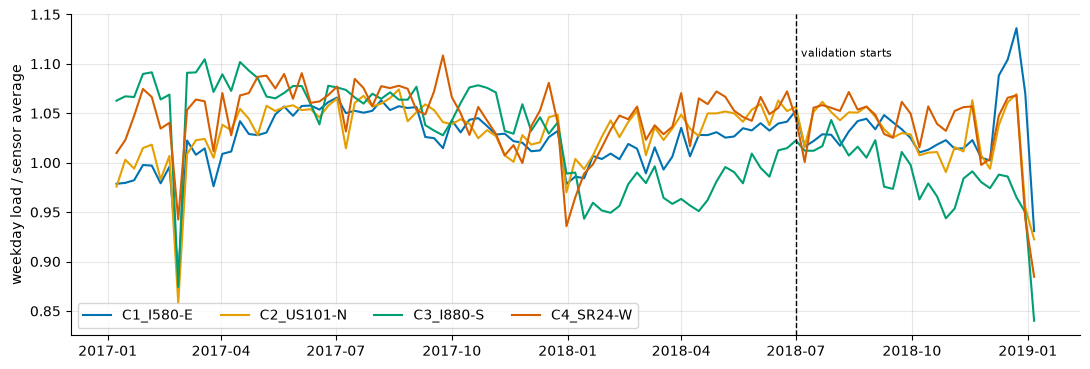

2018 vs 2017 change in mean daily flow by month (%), mean over corridors: [-2.2  1.7 -2.9 -2.1 -2.7 -2.  -2.2 -2.1 -2.6 -3.  -2.   1.2]


In [23]:
wk = daily_rel[(dts == "Weekday")].resample("W").mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
for c in sorted(CCOL):
    ax.plot(wk.index, wk[c], color=CCOL[c], label=c)
ax.axvline(pd.Timestamp("2018-07-01"), color="k", ls="--", lw=1); ax.text(pd.Timestamp("2018-07-05"), ax.get_ylim()[1] * 0.97, "validation starts", va="top", fontsize=8)
ax.set_ylabel("weekday load / sensor average"); ax.legend(ncol=4, loc="lower left")
savefig(fig, "eda04_seasonality")
yoy = daily_rel.groupby([daily_rel.index.year, daily_rel.index.month]).mean()
yoy = (yoy.loc[2018].values / yoy.loc[2017].values - 1) * 100
print("2018 vs 2017 change in mean daily flow by month (%), mean over corridors:", np.round(yoy.mean(axis=1), 1))

## 6. Figure 5 · Does rain change traffic? (matched comparison)
Rain happens mostly in winter and on certain days, so a naive wet-vs-dry average is confounded. We compare wet and
dry rows **inside the same cell** (same corridor x hour x weekday-type x month) and average the ratios.
"Wet" = at least 0.5 mm in the last 3 h; "dry" = 0 mm. `y` is flow divided by the sensor's trailing 7-day mean.

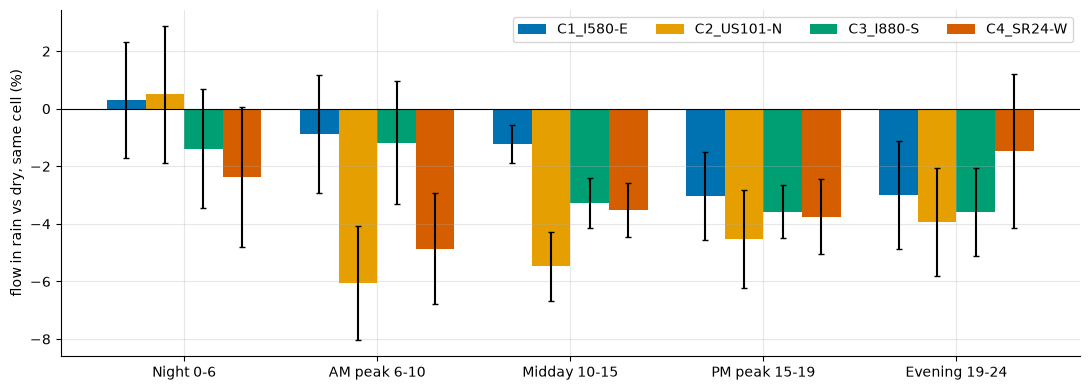

,corridor,band,effect_pct,ci95_pct,cells
0,C1_I580-E,Night 0-6,0.30,2.02,59.0
1,C1_I580-E,AM peak 6-10,-0.88,2.04,36.0
2,C1_I580-E,Midday 10-15,-1.22,0.67,49.0
3,C1_I580-E,PM peak 15-19,-3.04,1.54,40.0
4,C1_I580-E,Evening 19-24,-2.99,1.88,49.0
5,C2_US101-N,Night 0-6,0.50,2.38,45.0
6,C2_US101-N,AM peak 6-10,-6.05,1.99,39.0
7,C2_US101-N,Midday 10-15,-5.48,1.20,47.0
8,C2_US101-N,PM peak 15-19,-4.52,1.69,35.0
9,C2_US101-N,Evening 19-24,-3.92,1.88,43.0


Rows used: wet 86782 | dry 1205101


In [24]:
d = eda[["corridor", "tt_hour", "offday", "month", "rain_3h_mm", "y"]].copy()
d["wet"] = d["rain_3h_mm"] >= 0.5
d = d[d["wet"] | (d["rain_3h_mm"] == 0)]
d["hb"] = d["tt_hour"].astype(int)
d["band"] = pd.cut(d["tt_hour"], [0, 6, 10, 15, 19, 24], right=False, labels=["Night 0-6", "AM peak 6-10", "Midday 10-15", "PM peak 15-19", "Evening 19-24"])
g = d.groupby(["corridor", "band", "hb", "offday", "month", "wet"], observed=True)["y"].agg(["mean", "size"]).unstack("wet")
g = g.dropna()
g = g[(g[("size", True)] >= 30) & (g[("size", False)] >= 30)]
g["ratio"] = g[("mean", True)] / g[("mean", False)]
g["w"] = g[("size", True)]
def wmean(x):
    w = x["w"] / x["w"].sum()
    m = float((x["ratio"] * w).sum())
    sd = float(np.sqrt(((x["ratio"] - m) ** 2 * w).sum()))
    return pd.Series({"effect_pct": (m - 1) * 100, "ci95_pct": 1.96 * sd / np.sqrt(len(x)) * 100, "cells": len(x)})
eff = g.reset_index().groupby(["corridor", "band"], observed=True).apply(wmean).reset_index()
fig, ax = plt.subplots(figsize=(11, 4))
bands = list(eff["band"].cat.categories) if hasattr(eff["band"], "cat") else sorted(eff["band"].unique())
wd = 0.2
for i, c in enumerate(sorted(CCOL)):
    e = eff[eff["corridor"] == c].set_index("band").reindex(bands)
    ax.bar(np.arange(len(bands)) + (i - 1.5) * wd, e["effect_pct"], wd, yerr=e["ci95_pct"], color=CCOL[c], label=c, capsize=2)
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(len(bands))); ax.set_xticklabels(bands)
ax.set_ylabel("flow in rain vs dry, same cell (%)"); ax.legend(ncol=4)
savefig(fig, "eda05_rain_effect")
display(eff.round(2))
facts["rain_effect_pct_mean"] = float(eff["effect_pct"].mean())
print("Rows used: wet", int(d["wet"].sum()), "| dry", int((~d["wet"]).sum()))

## 7. Figure 6 · Spatial dependence between neighbouring sensors
We remove each sensor's typical (weekday x time-of-day) pattern, then correlate what is left. High correlation at
distance 1 says the sensor behind/ahead helps predict a sensor's surprises (this is why we have `nb_back`/`nb_ahead`).

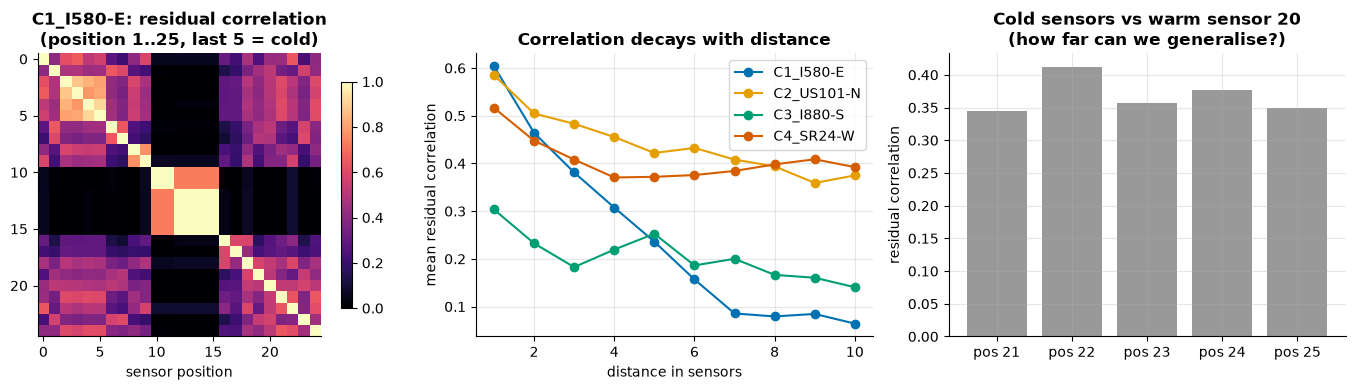

Mean residual correlation at gap 1: 0.502 | gap 5: 0.321


In [25]:
tod = F.index.dayofweek * 96 + F.index.hour * 4 + F.index.minute // 15
resid = (F / F.groupby(tod).transform("mean") - 1).replace([np.inf, -np.inf], np.nan)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
gapcorr = {}
for c in sorted(CCOL):
    cols = [k for k in F.columns if cmap[k] == c]
    cols = sorted(cols, key=lambda k: sensors.loc[k, "position"])
    R = resid[cols].corr(min_periods=2000).to_numpy()
    gapcorr[c] = [np.nanmean(np.diag(R, k)) for k in range(1, 11)]
    if c == "C1_I580-E":
        im = axes[0].imshow(R, vmin=0, vmax=1, cmap="magma"); axes[0].set_title(f"{c}: residual correlation\n(position 1..25, last 5 = cold)")
        axes[0].set_xlabel("sensor position"); axes[0].grid(False); fig.colorbar(im, ax=axes[0], shrink=0.8)
    axes[1].plot(range(1, 11), gapcorr[c], "o-", color=CCOL[c], label=c)
axes[1].set_xlabel("distance in sensors"); axes[1].set_ylabel("mean residual correlation"); axes[1].set_title("Correlation decays with distance"); axes[1].legend()
# cold sensors vs their nearest warm sensor (position 20) : how similar is a held-out sensor?
rows = []
for c in sorted(CCOL):
    cols = sorted([k for k in F.columns if cmap[k] == c], key=lambda k: sensors.loc[k, "position"])
    R = resid[cols].corr(min_periods=2000).to_numpy()
    rows.append([R[19, 20 + j] for j in range(5)])
axes[2].bar(np.arange(5), np.mean(rows, axis=0), color="#999999")
axes[2].set_xticks(range(5)); axes[2].set_xticklabels([f"pos {21 + j}" for j in range(5)])
axes[2].set_title("Cold sensors vs warm sensor 20\n(how far can we generalise?)"); axes[2].set_ylabel("residual correlation")
savefig(fig, "eda06_spatial_dependence")
facts["neighbour_corr_gap1"] = float(np.mean([v[0] for v in gapcorr.values()]))
print("Mean residual correlation at gap 1:", round(facts["neighbour_corr_gap1"], 3), "| gap 5:", round(float(np.mean([v[4] for v in gapcorr.values()])), 3))

## 8. Figure 7 · Temporal dependence and how forecasting difficulty grows with the horizon
Left: autocorrelation of flow (peaks at 24 h and 168 h = why same-time-last-week works). Right: error of simple
rules as the horizon grows. Persistence gets worse with horizon; the seasonal baselines do not depend on it.
Errors are WAPE (sum of absolute errors / sum of flow), all sensors, 2017-2018 only.

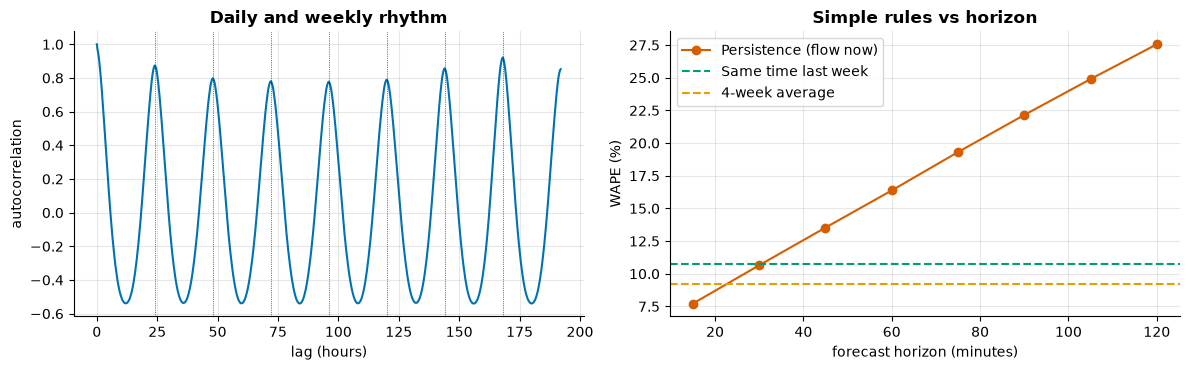

Persistence WAPE: 15 min 7.7%, 60 min 16.4% | last week 10.8% | 4-week avg 9.2% | crossover at ~30 min


In [26]:
Fv = F.to_numpy("float64")
lags = np.arange(0, 8 * 96 + 1)
sub = Fv[:, ::6][70 * 96:]                                          # 17 sensors, skip first 70 days
sub = np.where(np.isnan(sub), np.nanmean(sub, axis=0), sub)          # for the ACF only: fill gaps with the mean
sub = sub - sub.mean(axis=0)
n = sub.shape[0]
f = np.fft.rfft(sub, n=2 * n, axis=0)
acf = np.fft.irfft(f * np.conj(f), axis=0)[: len(lags)] / n / sub.var(axis=0)
acf = acf.mean(axis=1)
horizons = np.arange(1, 9)
def wape_lag(k):
    a, b = Fv[k:], Fv[:-k]
    ok = np.isfinite(a) & np.isfinite(b)
    return np.abs(a - b)[ok].sum() / np.abs(a)[ok].sum()
pers = [wape_lag(k) for k in horizons]
wk_err = wape_lag(672)
four = np.stack([Fv[4 * 672:] ] * 1)[0]
avg4 = np.nanmean(np.stack([Fv[(4 - j) * 672: len(Fv) - j * 672] for j in range(1, 5)]), axis=0)
okk = np.isfinite(four) & np.isfinite(avg4)
four_err = np.abs(four - avg4)[okk].sum() / np.abs(four)[okk].sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(lags / 4, acf, color="#0072B2"); axes[0].set_xlabel("lag (hours)"); axes[0].set_ylabel("autocorrelation")
for x in (24, 48, 72, 96, 120, 144, 168):
    axes[0].axvline(x, color="k", lw=0.5, ls=":")
axes[0].set_title("Daily and weekly rhythm")
axes[1].plot(horizons * 15, np.array(pers) * 100, "o-", color="#D55E00", label="Persistence (flow now)")
axes[1].axhline(wk_err * 100, color="#009E73", ls="--", label="Same time last week")
axes[1].axhline(four_err * 100, color="#E69F00", ls="--", label="4-week average")
axes[1].set_xlabel("forecast horizon (minutes)"); axes[1].set_ylabel("WAPE (%)"); axes[1].legend(); axes[1].set_title("Simple rules vs horizon")
savefig(fig, "eda07_temporal_dependence")
facts.update({"wape_persist_15": pers[0], "wape_persist_60": pers[3], "wape_lastweek": wk_err, "wape_4wk": four_err})
cross = next((int(k * 15) for k, v in zip(horizons, pers) if v > four_err), None)
print(f"Persistence WAPE: 15 min {pers[0]:.1%}, 60 min {pers[3]:.1%} | last week {wk_err:.1%} | 4-week avg {four_err:.1%} | crossover at ~{cross} min")

## 9. Figure 8 · Lanes and capacity
Flow per lane by lane count, and the maximum observed per lane against the fault threshold (600 vehicles per lane
per 15 min). If real flow rarely approaches the threshold, the fault rule only removes impossible readings.

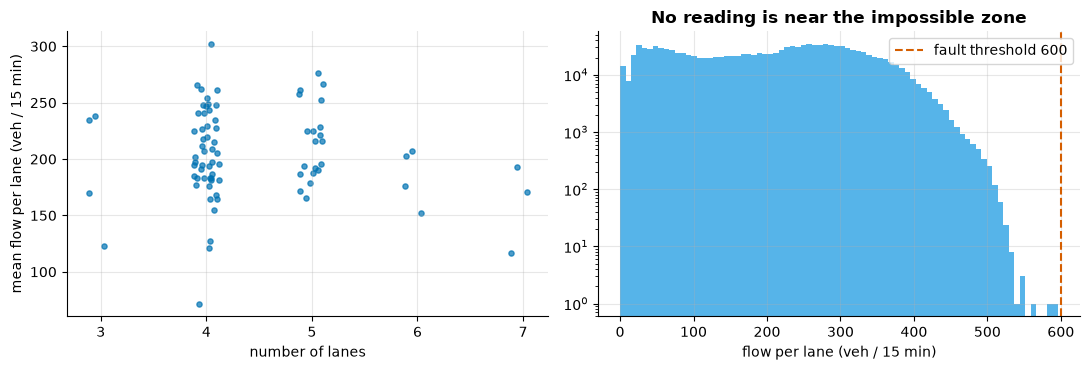

Largest observed flow per lane: 596.2 | share above 450: 0.004232708933717579


In [27]:
d = eda[["ID2", "corridor", "lanes", "y_raw"]].copy()
d["per_lane"] = d["y_raw"] / d["lanes"]
sm = d.groupby("ID2").agg(lanes=("lanes", "first"), corridor=("corridor", "first"), mean_pl=("per_lane", "mean"), p99_pl=("per_lane", lambda s: s.quantile(.99)))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for L in sorted(sm["lanes"].unique()):
    axes[0].scatter(np.full((sm["lanes"] == L).sum(), L) + np.random.default_rng(0).uniform(-.12, .12, (sm["lanes"] == L).sum()),
                    sm.loc[sm["lanes"] == L, "mean_pl"], s=14, color="#0072B2", alpha=0.7)
axes[0].set_xlabel("number of lanes"); axes[0].set_ylabel("mean flow per lane (veh / 15 min)"); axes[0].set_xticks(sorted(sm["lanes"].unique()))
axes[1].hist(d["per_lane"], bins=80, color="#56B4E9"); axes[1].set_yscale("log")
axes[1].axvline(600, color="#D55E00", ls="--", label="fault threshold 600"); axes[1].legend()
axes[1].set_xlabel("flow per lane (veh / 15 min)"); axes[1].set_title("No reading is near the impossible zone")
savefig(fig, "eda08_lanes_capacity")
print("Largest observed flow per lane:", round(float(d["per_lane"].max()), 1), "| share above 450:", float((d["per_lane"] > 450).mean()))

## 10. Figure 9 · Missing data: when, where and for how long
Monthly missing share per sensor, and how long the gaps last. Short gaps are bridged by forward-fill; long gaps rely
on last week / the trailing median. Targets that are missing are never imputed; they are excluded.

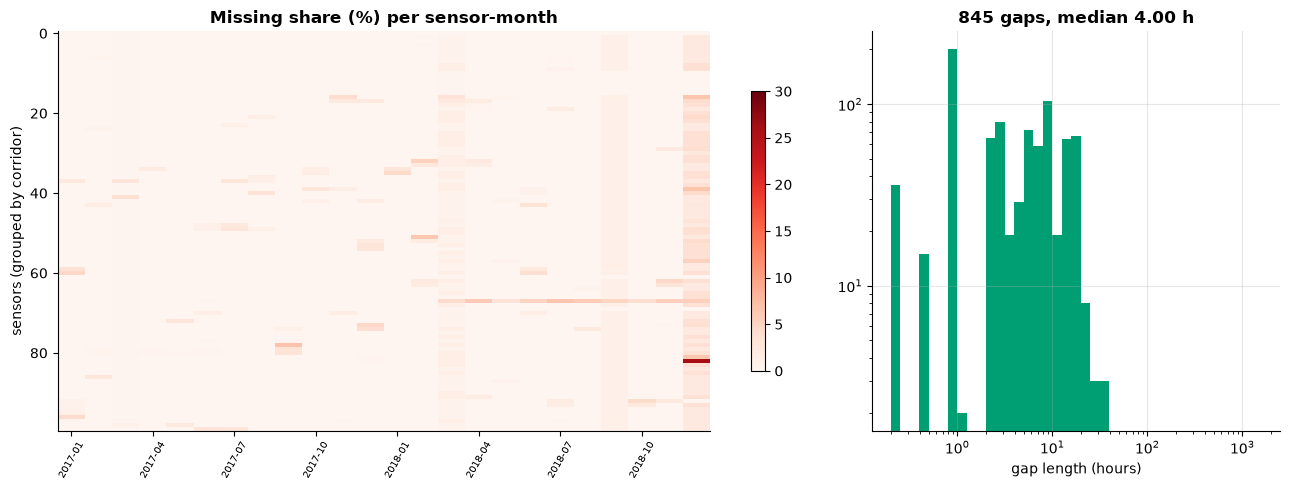

Gaps: median 4.00 h | share longer than 1 h 70.3% | longest 34 h


In [28]:
order_cols = sorted(F.columns, key=lambda k: (cmap[k], sensors.loc[k, "position"]))
mm = F[order_cols].isna().groupby(F.index.to_period("M")).mean().T
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 1]})
im = axes[0].imshow(mm.to_numpy() * 100, aspect="auto", cmap="Reds", vmin=0, vmax=30)
axes[0].set_xticks(range(0, mm.shape[1], 3)); axes[0].set_xticklabels([str(p) for p in mm.columns[::3]], rotation=60, fontsize=7)
axes[0].set_ylabel("sensors (grouped by corridor)"); axes[0].set_title("Missing share (%) per sensor-month"); axes[0].grid(False)
fig.colorbar(im, ax=axes[0], shrink=0.7)
runs = []
isn = np.isnan(Fv)
for j in range(Fv.shape[1]):
    x = np.concatenate([[0], isn[:, j].astype(np.int8), [0]])
    dx = np.diff(x)
    s, e = np.flatnonzero(dx == 1), np.flatnonzero(dx == -1)
    runs.extend((e - s) / 4.0)
runs = np.array(runs)
axes[1].hist(runs, bins=np.logspace(-0.7, 3.2, 40), color="#009E73"); axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("gap length (hours)"); axes[1].set_title(f"{len(runs):,} gaps, median {np.median(runs):.2f} h")
savefig(fig, "eda09_missing_data")
facts["gap_median_hours"] = float(np.median(runs)); facts["gap_share_longer_than_1h"] = float((runs > 1).mean())
print(f"Gaps: median {np.median(runs):.2f} h | share longer than 1 h {(runs > 1).mean():.1%} | longest {runs.max():.0f} h")

## 11. Figure 10 · Where is the forecasting problem hard?
Persistence error (WAPE) by weekday and hour: error concentrates in the rush-hour ramps, where flow changes fast.
Right: the 15-minute change in scaled flow has heavy tails; most steps are tiny, a few are large.

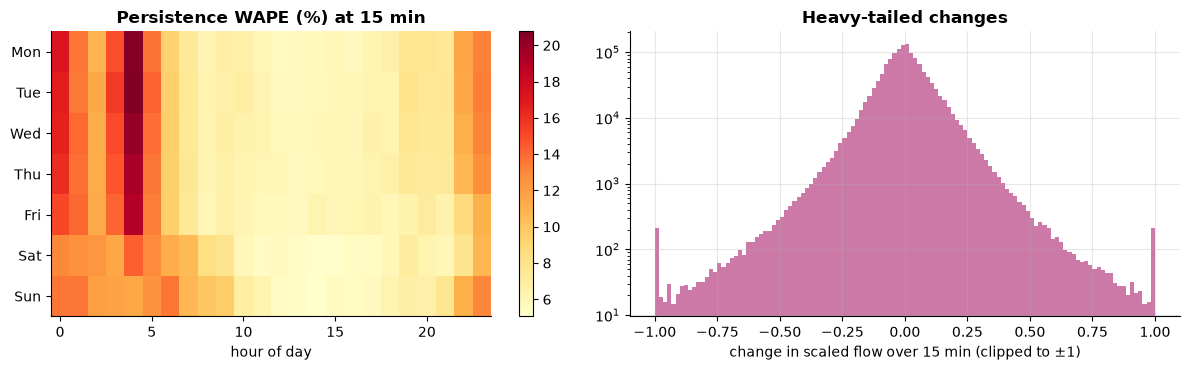

|15-min change| (scaled) median / p90 / p99: [0.053 0.172 0.388]


In [29]:
e = (eda["flow_t"] * eda["sc"] - eda["y_raw"]).abs()
grid = pd.DataFrame({"e": e, "y": eda["y_raw"], "dow": eda["target_time"].dt.dayofweek, "hr": eda["target_time"].dt.hour})
wp = grid.groupby(["dow", "hr"]).apply(lambda x: x["e"].sum() / x["y"].sum()).unstack()
chg = (eda["y"] - eda["flow_t"]).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
im = axes[0].imshow(wp.to_numpy() * 100, aspect="auto", cmap="YlOrRd", extent=[-0.5, 23.5, 6.5, -0.5])
axes[0].set_yticks(range(7)); axes[0].set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); axes[0].set_xlabel("hour of day")
axes[0].set_title("Persistence WAPE (%) at 15 min"); axes[0].grid(False); fig.colorbar(im, ax=axes[0])
axes[1].hist(np.clip(chg, -1, 1), bins=120, color="#CC79A7"); axes[1].set_yscale("log")
axes[1].set_xlabel("change in scaled flow over 15 min (clipped to ±1)"); axes[1].set_title("Heavy-tailed changes")
savefig(fig, "eda10_error_structure")
q = np.quantile(np.abs(chg), [.5, .9, .99])
print("|15-min change| (scaled) median / p90 / p99:", np.round(q, 3))
facts["abs_change_p50_p90_p99"] = [float(v) for v in q]

## 12. Figure 11 · Which features move with the target?
Spearman correlation of each feature with (a) the scaled target and (b) the **change** from now (`y - flow_t`).
The second is what a model must actually learn beyond persistence. Right: correlation between features
(strong blocks = redundancy, the reason PCA is on the model list).

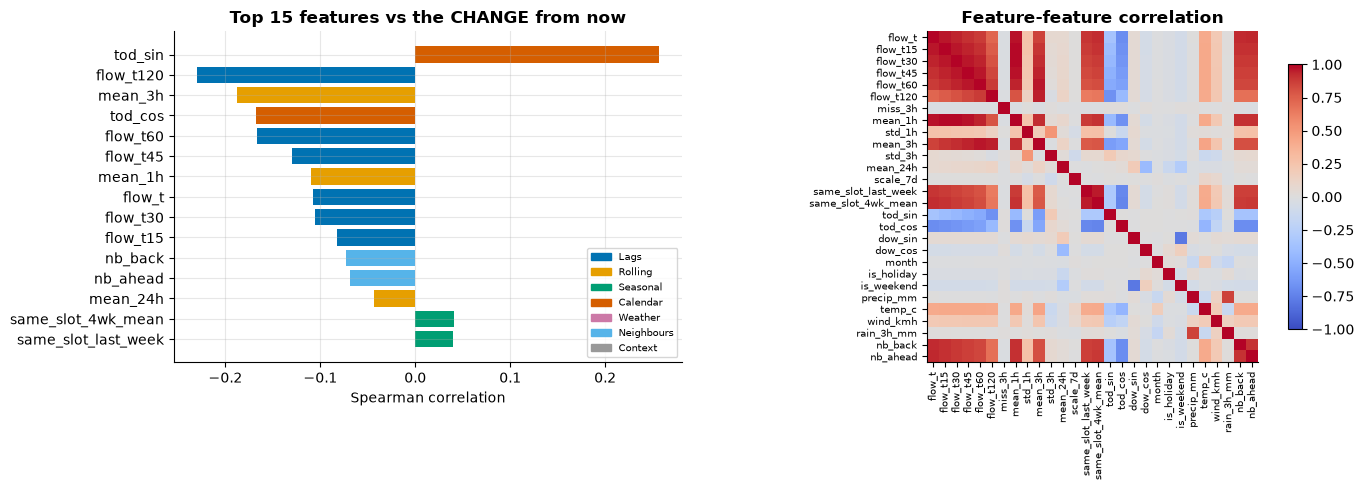

,corr_with_y,corr_with_change,group
tod_sin,-0.306,0.257,Calendar
flow_t120,0.673,-0.230,Lags
mean_3h,0.816,-0.187,Rolling
tod_cos,-0.716,-0.168,Calendar
flow_t60,0.844,-0.167,Lags
flow_t45,0.881,-0.130,Lags
mean_1h,0.940,-0.110,Rolling
flow_t,0.962,-0.108,Lags
flow_t30,0.912,-0.105,Lags
flow_t15,0.939,-0.082,Lags


In [30]:
from src.features import ALL_FEATURES, FEATURE_GROUPS
gmap = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
GCOL = dict(zip(FEATURE_GROUPS, ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#999999"]))
s = eda.sample(150_000, random_state=0)
Xs = s[ALL_FEATURES].astype("float64")
c_y = Xs.apply(lambda col: col.corr(s["y"], method="spearman"))
c_d = Xs.apply(lambda col: col.corr(s["y"] - s["flow_t"], method="spearman"))
top = c_d.abs().sort_values(ascending=False).head(15).index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].barh(top, c_d[top], color=[GCOL[gmap[f]] for f in top]); axes[0].set_title("Top 15 features vs the CHANGE from now")
axes[0].set_xlabel("Spearman correlation")
cm = Xs.drop(columns=["has_back", "has_ahead", "lanes"]).corr(method="spearman")
im = axes[1].imshow(cm.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1); axes[1].grid(False)
axes[1].set_xticks(range(len(cm))); axes[1].set_xticklabels(cm.columns, rotation=90, fontsize=7)
axes[1].set_yticks(range(len(cm))); axes[1].set_yticklabels(cm.columns, fontsize=7); axes[1].set_title("Feature-feature correlation")
fig.colorbar(im, ax=axes[1], shrink=0.8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GCOL.values()]
axes[0].legend(handles, GCOL.keys(), fontsize=7, loc="lower right")
savefig(fig, "eda11_feature_relationships")
display(pd.DataFrame({"corr_with_y": c_y, "corr_with_change": c_d, "group": pd.Series(gmap)}).round(3).sort_values("corr_with_change", key=abs, ascending=False).head(12))

## 13. Save the headline numbers
These feed the report text (so the numbers in the report always match the figures).

In [31]:
fx = pd.Series(facts, dtype="object")
fx.to_csv(ev.RESULTS / "eda_facts.csv", header=["value"])
display(fx)
print("\nFigures saved:")
for p in sorted(ev.FIGS.glob("eda*.png")):
    print(" ", p.name)

missing_pct_2017_2018                              0.29492
weekend_vs_weekday_ratio                          0.855171
rain_effect_pct_mean                             -2.813826
neighbour_corr_gap1                               0.502338
wape_persist_15                                   0.077212
wape_persist_60                                   0.163752
wape_lastweek                                     0.107698
wape_4wk                                          0.092182
gap_median_hours                                       4.0
gap_share_longer_than_1h                          0.702959
abs_change_p50_p90_p99      [0.052732, 0.172217, 0.387711]
dtype: object


Figures saved:
  eda01_daily_profile.png
  eda02_weekly_heatmap.png
  eda03_day_types.png
  eda04_seasonality.png
  eda05_rain_effect.png
  eda06_spatial_dependence.png
  eda07_temporal_dependence.png
  eda08_lanes_capacity.png
  eda09_missing_data.png
  eda10_error_structure.png
  eda11_feature_relationships.png
  eda_daily_profile.png
